# P3 – Anticiper la consommation d'énergie des bâtiments de Seattle
## Notebook 1/2 : analyse exploratoire

**Objectif :** compréhension du jeu de données, choix de la cible et sélection des bâtiments pertinents et fiables, avant la modélisation.

1. Import des modules, chargement et premier aperçu (`head`, `info`)
2. Sens des colonnes, colonnes majoritairement vides ou constantes
3. Choix de la cible
4. Filtrage des bâtiments, avec la trace du nombre de lignes
5. Description des bâtiments : usages, quartiers, surfaces, âges
6. Différences entre bâtiments mono-usage et multi-usages
7. Bâtiments atypiques et incohérences métier (pairplot, boxplots)
8. Synthèse et export

Feature engineering, préparation des features et modélisation : notebook 2.

# Analyse Exploratoire

### Import des modules

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chemins relatifs : le notebook fonctionne sur n'importe quel poste
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "2016_Building_Energy_Benchmarking.csv"
OUT = ROOT / "data" / "processed" / "P3_df_clean_191026.csv"
FIG = ROOT / "reports" / "figures_191026"
FIG.mkdir(parents=True, exist_ok=True)

TARGET = "SiteEnergyUse(kBtu)"

BLEU, ORANGE, GRIS, ENCRE = "#2a78d6", "#eb6834", "#f0efec", "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 200,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
    }
)
pd.set_option("display.max_columns", 50)

### Analyse Exploratoire

In [2]:
building_consumption = pd.read_csv(RAW)
print(
    f"{building_consumption.shape[0]:,} bâtiments x {building_consumption.shape[1]} colonnes"
)

3,376 bâtiments x 46 colonnes


In [3]:
# On regarde comment un bâtiment est défini dans ce jeu de données
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

#### Analyse détaillée

### 1. Sens des colonnes

Regroupement des 46 colonnes par famille, pour identifier celles qui sont utilisables :

| Famille | Exemples | Utilisable comme feature ? |
|---|---|---|
| Identification | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber` | Non (identifiants, texte libre) |
| Localisation | `Neighborhood`, `Latitude`, `Longitude`, `ZipCode` | Oui |
| Structure | `PropertyGFABuilding(s)`, `NumberofFloors`, `NumberofBuildings`, `YearBuilt` | Oui |
| Usages | `BuildingType`, `PrimaryPropertyType`, `LargestPropertyUseType`, `ListOfAllPropertyUseTypes` | Oui |
| Énergie mesurée | `Electricity(kBtu)`, `NaturalGas(kBtu)`, `SiteEUI`, `ENERGYSTARScore`, `TotalGHGEmissions` | **Non : fuite de données** |
| Qualité du relevé | `ComplianceStatus`, `Outlier`, `DefaultData` | Non : utilisées seulement pour filtrer |

**Règle anti-fuite :** une feature n'est acceptable que si elle est connue **avant** le relevé de consommation. Les quantités d'énergie mesurées, l'intensité (EUI), les émissions et l'ENERGY STAR Score (calculé par l'EPA à partir de la consommation réelle) sont donc exclus. Seule la **présence** d'une source d'énergie (gaz, vapeur) est une information structurelle autorisée.

### 2. Colonnes majoritairement vides ou constantes

Pour chaque colonne : part de valeurs manquantes, nombre de valeurs distinctes et, avec `value_counts()`, part de la valeur la plus fréquente. Liste des colonnes vides à plus de 50 %, constantes ou dominées à plus de 95 % par une seule valeur.

In [5]:
profil = pd.DataFrame(
    {
        "% manquant": building_consumption.isna().mean() * 100,
        "Valeurs distinctes": building_consumption.nunique(),
        "Valeur la plus fréquente (%)": building_consumption.apply(
            lambda col: col.value_counts(normalize=True, dropna=False).iloc[0] * 100
        ),
    }
).round(1)
a_examiner = profil[
    (profil["% manquant"] > 50)
    | (profil["Valeurs distinctes"] <= 1)
    | (profil["Valeur la plus fréquente (%)"] > 95)
]
a_examiner.sort_values("% manquant", ascending=False)

,% manquant,Valeurs distinctes,Valeur la plus fréquente (%)
Comments,100.0,0,100.0
Outlier,99.1,2,99.1
YearsENERGYSTARCertified,96.5,65,96.5
ThirdLargestPropertyUseType,82.3,44,82.3
ThirdLargestPropertyUseTypeGFA,82.3,501,82.3
SecondLargestPropertyUseTypeGFA,50.3,1352,50.3
SecondLargestPropertyUseType,50.3,50,50.3
SteamUse(kBtu),0.3,131,95.9
DataYear,0.0,1,100.0
City,0.0,1,100.0


In [6]:
for col in ["DataYear", "City", "State", "DefaultData", "ComplianceStatus", "Outlier"]:
    print(f"{col:17s}", building_consumption[col].value_counts(dropna=False).to_dict())

DataYear          {2016: 3376}
City              {'Seattle': 3376}
State             {'WA': 3376}
DefaultData       {False: 3263, True: 113}
ComplianceStatus  {'Compliant': 3211, 'Error - Correct Default Data': 113, 'Non-Compliant': 37, 'Missing Data': 15}
Outlier           {nan: 3344, 'Low outlier': 23, 'High outlier': 9}


**Conclusions :**
- `Comments` est entièrement vide, et `DataYear`, `City` et `State` sont constantes (2016, Seattle, WA) : aucune information, suppression ;
- `YearsENERGYSTARCertified` est vide à 96,5 % et liée à l'ENERGY STAR Score : suppression ;
- les deuxième et troisième usages sont vides à 50 % et 82 %. Ce n'est pas une erreur : beaucoup de bâtiments n'ont qu'un usage. Pas d'utilisation directe : l'information sera résumée par le nombre d'usages et la part de l'usage principal (notebook 2) ;
- `Outlier` (vide à 99 %), `ComplianceStatus` (95 % « Compliant ») et `DefaultData` (97 % « False ») décrivent la qualité du relevé, pas les bâtiments : utilisation pour filtrer, pas comme features ;
- `SteamUse(kBtu)` vaut 0 pour environ 96 % des bâtiments : peu de bâtiments sont raccordés au réseau de vapeur. C'est une consommation mesurée, donc exclue des features, mais sa **présence** deviendra la feature `HasSteam`.

**Pas de suppression des lignes** contenant des valeurs manquantes : trop de bâtiments seraient perdus, et les quelques trous restants seront imputés dans le pipeline de modélisation.

### 3. Choix de la cible

Plusieurs colonnes peuvent servir de cible : `SiteEnergyUse(kBtu)`, sa version normalisée météo `SiteEnergyUseWN(kBtu)`, les intensités (`SiteEUI`, `SourceEUI`) ou les émissions. La mission demande d'en choisir **une seule** et parle de « consommation totale d'énergie ». Comparaison des deux candidates principales :

In [7]:
nr = building_consumption[
    ~building_consumption["BuildingType"].str.contains("Multifamily", na=False)
]
site, wn = nr["SiteEnergyUse(kBtu)"], nr["SiteEnergyUseWN(kBtu)"]
somme_sources = (
    nr[["Electricity(kBtu)", "NaturalGas(kBtu)", "SteamUse(kBtu)"]]
    .fillna(0)
    .sum(axis=1)
)
ecart = (somme_sources - site).abs() / site.where(site > 0)

pd.Series(
    {
        "Valeurs nulles : SiteEnergyUse": int((site == 0).sum()),
        "Valeurs nulles : SiteEnergyUseWN": int((wn == 0).sum()),
        "WN = 0 alors que la consommation mesurée > 0": int(
            ((wn == 0) & (site > 0)).sum()
        ),
        "Ratio médian WN / consommation mesurée": round(
            (wn / site.where(site > 0)).median(), 3
        ),
        "Écart médian entre somme des sources et SiteEnergyUse (%)": round(
            ecart.median() * 100, 2
        ),
    }
).to_frame("Valeur")

,Valeur
Valeurs nulles : SiteEnergyUse,16.00
Valeurs nulles : SiteEnergyUseWN,25.00
WN = 0 alors que la consommation mesurée > 0,9.00
Ratio médian WN / consommation mesurée,1.04
Écart médian entre somme des sources et SiteEnergyUse (%),0.00


**Choix de `SiteEnergyUse(kBtu)`**, la consommation totale mesurée sur site :
- c'est exactement ce que demande la mission (consommation totale), et elle est égale à la somme électricité + gaz + vapeur ;
- la version `WN` est une **correction calculée** par le logiciel de la ville, pas une mesure : elle vaut 0 pour des bâtiments qui consomment réellement (normalisation impossible) ;
- tous les bâtiments sont à Seattle, sur la même année 2016 : ils ont subi **la même météo**, la normalisation n'apporte donc rien pour comparer les bâtiments entre eux ;
- les intensités (EUI) mesurent une consommation par pied carré, pas la consommation totale ; la version « Source » inclut les pertes de production et de transport.


### 4. Filtrage des bâtiments

Trace du nombre de lignes avant et après chaque filtre. Les valeurs extrêmes de consommation sont traitées dans le notebook 2, à l'étape « Préparation des features ».

In [8]:
building_consumption["BuildingType"].value_counts().to_frame(
    "Nombre de bâtiments"
).sort_values("Nombre de bâtiments", ascending=False)

,Nombre de bâtiments
BuildingType,
NonResidential,1460
Multifamily LR (1-4),1018
Multifamily MR (5-9),580
Multifamily HR (10+),110
SPS-District K-12,98
Nonresidential COS,85
Campus,24
Nonresidential WA,1


In [9]:
suivi = []


def etape(data, masque, libelle):
    """Applique un filtre et enregistre le nombre de lignes avant/après."""
    avant = len(data)
    data = data[masque]
    suivi.append(
        {
            "Étape": libelle,
            "Avant": avant,
            "Après": len(data),
            "Supprimés": avant - len(data),
        }
    )
    return data


RESIDENTIEL = [
    "Residence Hall",
    "Low-Rise Multifamily",
    "Mid-Rise Multifamily",
    "High-Rise Multifamily",
]

df = building_consumption.copy()
df = etape(
    df,
    ~df["BuildingType"].str.contains("Multifamily", na=False),
    "Bâtiments non résidentiels (BuildingType)",
)
df = etape(
    df,
    ~df["PrimaryPropertyType"].isin(RESIDENTIEL),
    "Usage principal non résidentiel (résidences étudiantes, logements)",
)
df = etape(
    df, df["ComplianceStatus"] == "Compliant", "Relevé conforme (ComplianceStatus)"
)
df = etape(
    df, df["Outlier"].isna(), "Non signalé comme aberrant par la ville (Outlier)"
)
df = etape(
    df, df[TARGET].notna() & (df[TARGET] > 0), "Consommation mesurée renseignée et > 0"
)
df = etape(
    df, df["LargestPropertyUseType"] != "Parking", "Usage principal autre que parking"
)
df = etape(df, df["PropertyGFABuilding(s)"] > 0, "Surface bâtie > 0")
pd.DataFrame(suivi)

,Étape,Avant,Après,Supprimés
0,Bâtiments non résidentiels (BuildingType),3376,1668,1708
1,Usage principal non résidentiel (résidences ét...,1668,1644,24
2,Relevé conforme (ComplianceStatus),1644,1525,119
3,Non signalé comme aberrant par la ville (Outlier),1525,1525,0
4,Consommation mesurée renseignée et > 0,1525,1525,0
5,Usage principal autre que parking,1525,1495,30
6,Surface bâtie > 0,1495,1495,0


**Choix de filtrage :**
- **Non résidentiel** : la mission porte sur les bâtiments non destinés à l'habitation. Sur les 8 types de bâtiments, 3 sont résidentiels (Multifamily LR, MR et HR : 1 018 + 580 + 110 = 1 708 bâtiments, exactement le nombre retiré par ce premier filtre). Types conservés : NonResidential (1 460), SPS-District K-12 (98, écoles publiques), Nonresidential COS (85, bâtiments de la ville), Campus (24) et Nonresidential WA (1). Exclusion aussi des résidences étudiantes et des quelques logements mal classés.
- **Relevé conforme** : les statuts « Non-Compliant », « Missing Data » et « Error - Correct Default Data » signalent des relevés incomplets ou des surfaces saisies par défaut. Ces bâtiments ne sont pas fiables pour l'apprentissage.
- **Parking** : un parking consomme très peu par rapport à sa surface. Exclusion des bâtiments dont l'usage principal est le parking, et utilisation de la **surface bâtie hors parking** `PropertyGFABuilding(s)` au lieu de la surface totale.

### 5. Description des bâtiments retenus

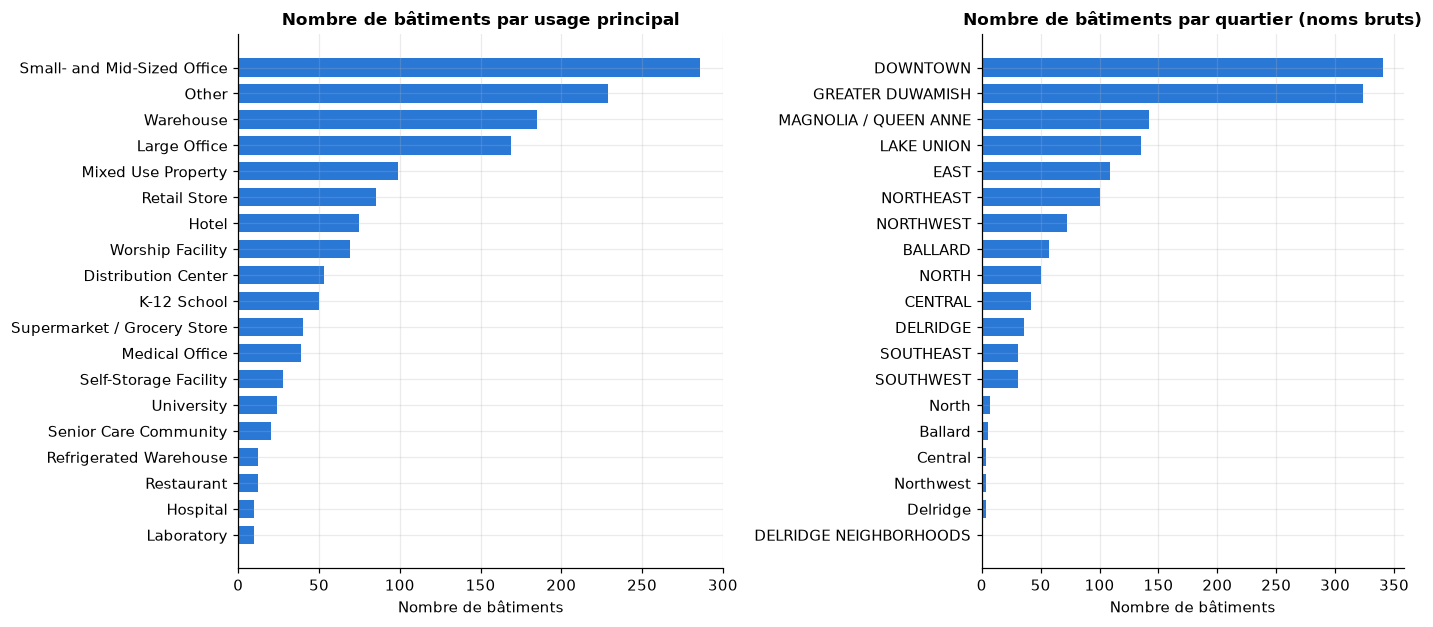

In [10]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [1.15, 1]}
)
types = df["PrimaryPropertyType"].value_counts().sort_values()
axes[0].barh(types.index, types.values, color=BLEU, height=0.7)
axes[0].set(
    title="Nombre de bâtiments par usage principal", xlabel="Nombre de bâtiments"
)
quartiers = df["Neighborhood"].value_counts().sort_values()
axes[1].barh(quartiers.index, quartiers.values, color=BLEU, height=0.7)
axes[1].set(
    title="Nombre de bâtiments par quartier (noms bruts)", xlabel="Nombre de bâtiments"
)
plt.tight_layout()
plt.savefig(FIG / "eda_01_usages_quartiers.png", bbox_inches="tight")
plt.show()

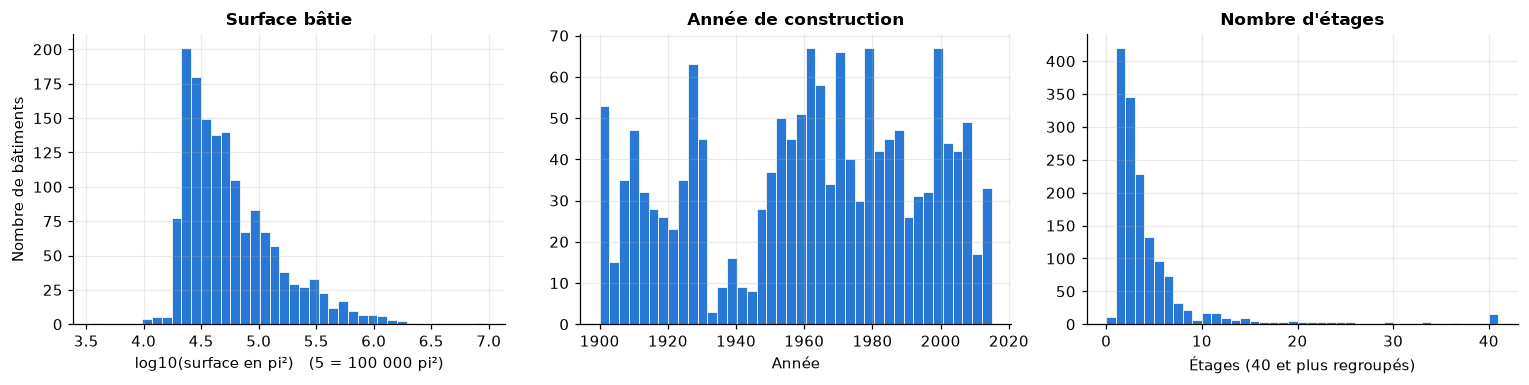

,count,mean,std,min,25%,50%,75%,max
PropertyGFABuilding(s),1495.0,107783.2,297253.7,3636.0,27857.0,45864.0,94201.0,9320156.0
NumberofFloors,1495.0,4.3,6.9,0.0,1.0,2.0,4.0,99.0
NumberofBuildings,1495.0,1.2,3.1,0.0,1.0,1.0,1.0,111.0
YearBuilt,1495.0,1961.0,32.6,1900.0,1929.5,1965.0,1988.0,2015.0
SiteEnergyUse(kBtu),1495.0,8805958.9,31711815.3,57133.2,1233459.2,2662054.2,7245931.5,873923712.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(
    np.log10(df["PropertyGFABuilding(s)"]),
    bins=40,
    color=BLEU,
    edgecolor="white",
    linewidth=0.5,
)
axes[0].set(
    title="Surface bâtie",
    xlabel="log10(surface en pi²)   (5 = 100 000 pi²)",
    ylabel="Nombre de bâtiments",
)
axes[1].hist(df["YearBuilt"], bins=40, color=BLEU, edgecolor="white", linewidth=0.5)
axes[1].set(title="Année de construction", xlabel="Année")
axes[2].hist(
    df["NumberofFloors"].clip(upper=40),
    bins=range(0, 42),
    color=BLEU,
    edgecolor="white",
    linewidth=0.5,
)
axes[2].set(title="Nombre d'étages", xlabel="Étages (40 et plus regroupés)")
plt.tight_layout()
plt.savefig(FIG / "eda_02_structure.png", bbox_inches="tight")
plt.show()

df[
    [
        "PropertyGFABuilding(s)",
        "NumberofFloors",
        "NumberofBuildings",
        "YearBuilt",
        TARGET,
    ]
].describe().T.round(1)

**Points clés :**
- **les usages sont très déséquilibrés** : les bureaux petits et moyens (286), la catégorie fourre-tout « Other » (229), les entrepôts (185) et les grands bureaux (169) représentent 58 % des bâtiments, alors que les hôpitaux et les laboratoires n'en comptent que 10 chacun. Les catégories rares seront regroupées à l'encodage ;
- **les quartiers ont des noms incohérents** : « North » et « NORTH », ou « Delridge », « DELRIDGE » et « DELRIDGE NEIGHBORHOODS » désignent les mêmes quartiers. Harmonisation dans le notebook 2 ;
- **la surface est très asymétrique** : médiane de 45 900 pi² pour une moyenne de 107 800 pi², et 16 bâtiments dépassent 1 million de pi². Il faudra passer la surface au log ;
- la moitié des bâtiments a 1 ou 2 étages, et un quart a été construit avant 1930 ;
- la consommation suit la même asymétrie : médiane de 2,7 millions de kBtu pour une moyenne de 8,8 millions. **Les 10 % de bâtiments les plus consommateurs représentent 61 % de la consommation totale.**

### 6. Bâtiments mono-usage et multi-usages

Comptage des usages déclarés dans `ListOfAllPropertyUseTypes`, sans le parking, pour comparer les bâtiments à un seul usage et ceux qui en ont plusieurs.

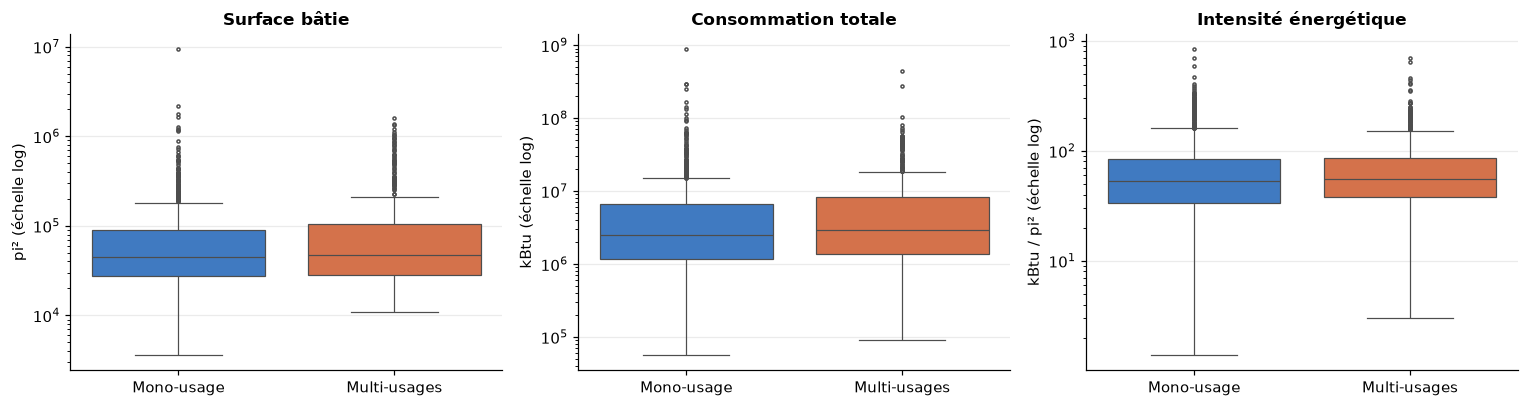

,Bâtiments,Surface médiane (pi²),Consommation médiane (kBtu),Intensité médiane (kBtu/pi²),Part (%)
Profil d'usage,,,,,
Mono-usage,914,45213.0,2538996.0,53.0,61.0
Multi-usages,581,47686.0,2886142.0,55.0,39.0


In [12]:
batiments = df.copy()
nb_usages = (
    batiments["ListOfAllPropertyUseTypes"]
    .fillna("")
    .str.split(",")
    .apply(lambda liste: sum(1 for u in liste if u.strip() and u.strip() != "Parking"))
)
batiments["Profil d'usage"] = np.where(nb_usages > 1, "Multi-usages", "Mono-usage")

synthese = batiments.groupby("Profil d'usage").agg(
    **{
        "Bâtiments": ("OSEBuildingID", "size"),
        "Surface médiane (pi²)": ("PropertyGFABuilding(s)", "median"),
        "Consommation médiane (kBtu)": (TARGET, "median"),
        "Intensité médiane (kBtu/pi²)": ("SiteEUI(kBtu/sf)", "median"),
    }
)
synthese["Part (%)"] = (synthese["Bâtiments"] / len(batiments) * 100).round(1)

couleurs_profil = {"Mono-usage": BLEU, "Multi-usages": ORANGE}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, titre, unite) in zip(
    axes,
    [
        ("PropertyGFABuilding(s)", "Surface bâtie", "pi²"),
        (TARGET, "Consommation totale", "kBtu"),
        ("SiteEUI(kBtu/sf)", "Intensité énergétique", "kBtu / pi²"),
    ],
):
    sns.boxplot(
        data=batiments,
        x="Profil d'usage",
        y=col,
        hue="Profil d'usage",
        palette=couleurs_profil,
        order=["Mono-usage", "Multi-usages"],
        legend=False,
        fliersize=2,
        linewidth=0.8,
        ax=ax,
    )
    ax.set(yscale="log", title=titre, xlabel="", ylabel=f"{unite} (échelle log)")
plt.tight_layout()
plt.savefig(FIG / "eda_03_mono_multi.png", bbox_inches="tight")
plt.show()
synthese.round(0)

**Points clés :** 61 % des bâtiments n'ont qu'un usage, 39 % en ont plusieurs. Les bâtiments multi-usages sont à peine plus grands (surface médiane de 47 700 pi² contre 45 200) et consomment un peu plus en médiane (2,9 millions de kBtu contre 2,5, soit +14 %), mais leur intensité énergétique est presque identique (55 contre 53 kBtu/pi²).

**Avoir plusieurs usages compte donc moins que la nature des usages eux-mêmes.** Cette information est tout de même conservée sous forme de features (nombre d'usages et part de l'usage principal) : le modèle mesurera son poids réel.

### 7. Bâtiments atypiques et incohérences métier

Le pairplot croise les principales variables numériques deux à deux pour repérer les bâtiments isolés du nuage. Puis examen de l'intensité énergétique par usage : à usage égal, un bâtiment très éloigné des autres est suspect.

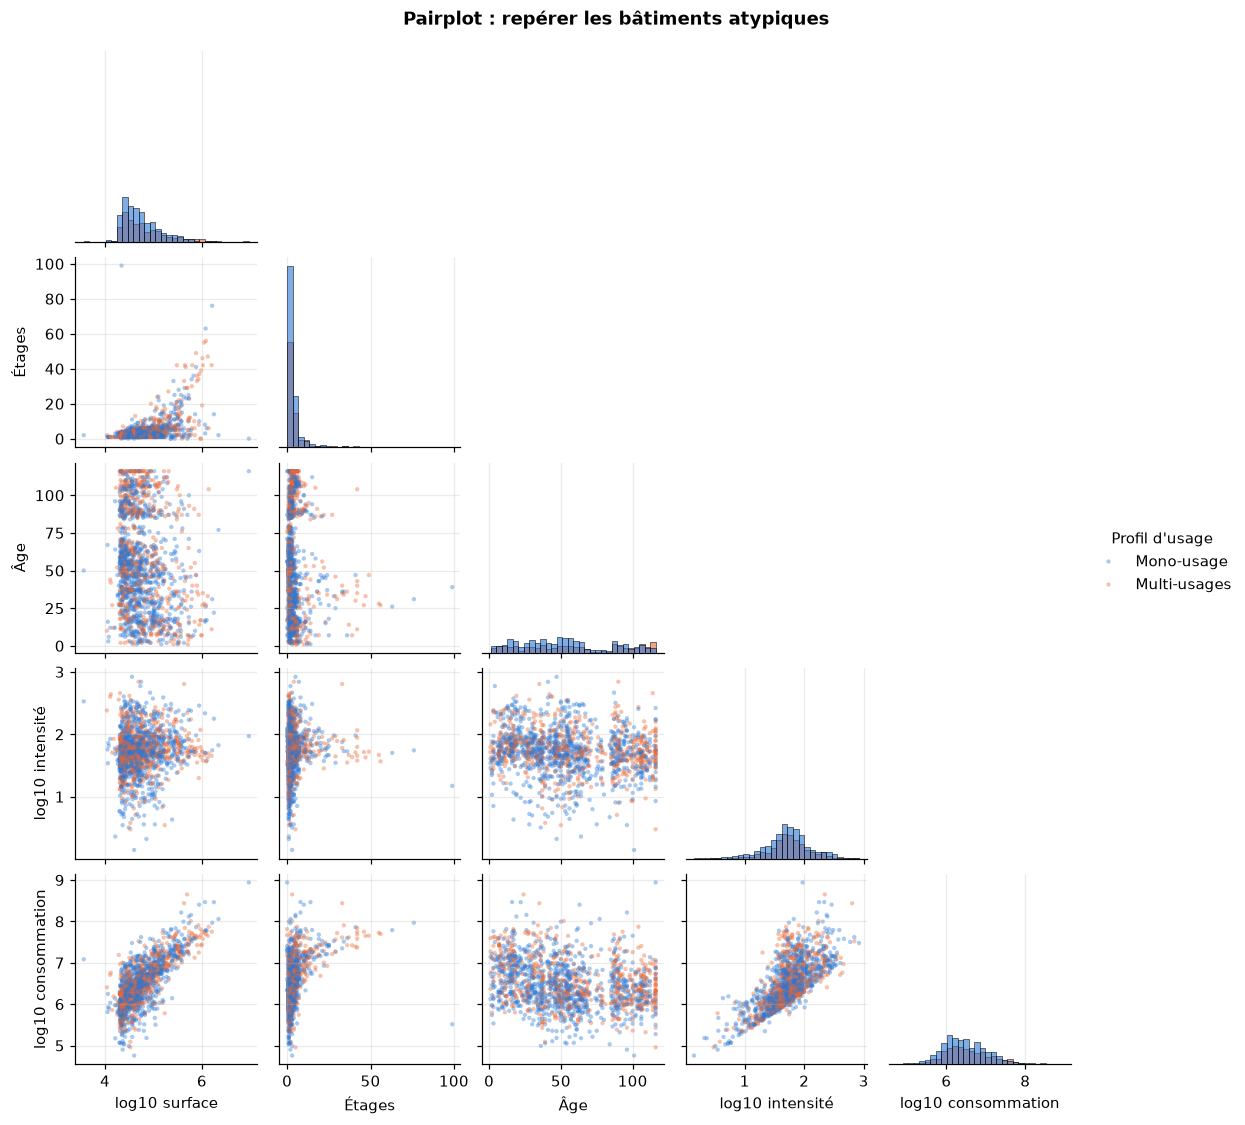

In [13]:
paire = pd.DataFrame(
    {
        "log10 surface": np.log10(df["PropertyGFABuilding(s)"]),
        "Étages": df["NumberofFloors"],
        "Âge": 2016 - df["YearBuilt"],
        "log10 intensité": np.log10(df["SiteEUI(kBtu/sf)"].clip(lower=0.1)),
        "log10 consommation": np.log10(df[TARGET]),
        "Profil d'usage": batiments["Profil d'usage"],
    }
)
g = sns.pairplot(
    paire,
    hue="Profil d'usage",
    palette=couleurs_profil,
    corner=True,
    diag_kind="hist",
    height=2.0,
    plot_kws=dict(s=8, alpha=0.4, edgecolor="none"),
    diag_kws=dict(bins=30, alpha=0.6),
)
g.fig.suptitle("Pairplot : repérer les bâtiments atypiques", y=1.02, fontweight="bold")
plt.savefig(FIG / "eda_04_pairplot.png", bbox_inches="tight")
plt.show()

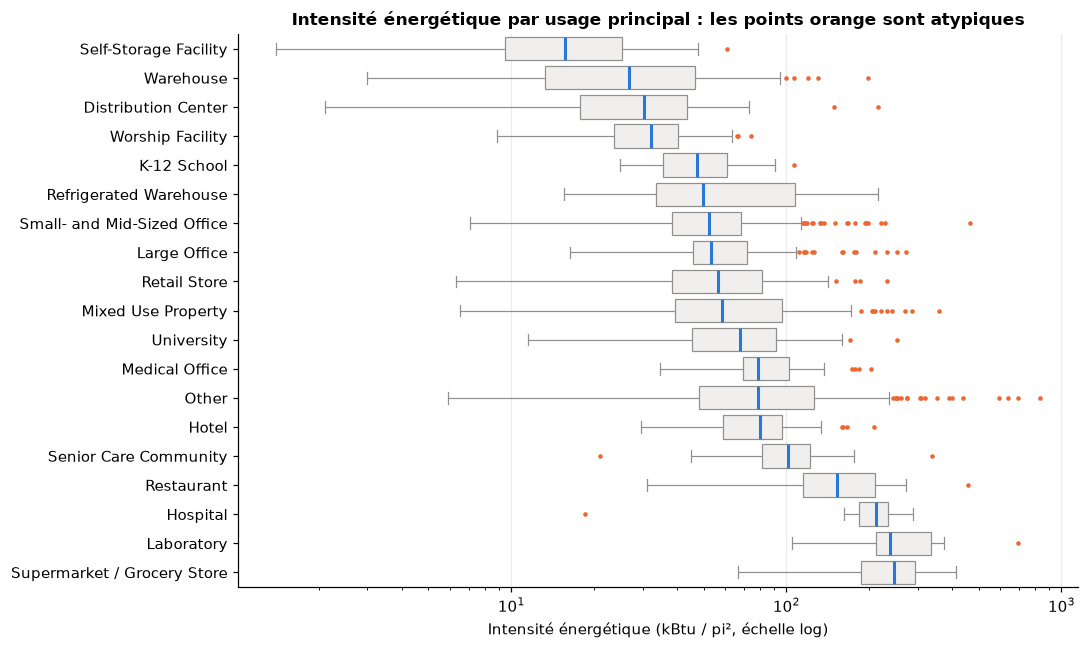

In [14]:
ordre = (
    df.groupby("PrimaryPropertyType")["SiteEUI(kBtu/sf)"].median().sort_values().index
)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df,
    y="PrimaryPropertyType",
    x="SiteEUI(kBtu/sf)",
    order=ordre,
    color=GRIS,
    linewidth=0.8,
    fliersize=3,
    flierprops=dict(markerfacecolor=ORANGE, markeredgecolor="none"),
    medianprops=dict(color=BLEU, linewidth=2),
    ax=ax,
)
ax.set(
    xscale="log",
    title="Intensité énergétique par usage principal : les points orange sont atypiques",
    xlabel="Intensité énergétique (kBtu / pi², échelle log)",
    ylabel="",
)
plt.tight_layout()
plt.savefig(FIG / "eda_05_intensite_par_usage.png", bbox_inches="tight")
plt.show()

In [15]:
p1, p99 = df["SiteEUI(kBtu/sf)"].quantile([0.01, 0.99])
quartiers_harmonises = (
    df["Neighborhood"].str.upper().replace({"DELRIDGE NEIGHBORHOODS": "DELRIDGE"})
)
incoherences = pd.Series(
    {
        "0 étage déclaré": int((df["NumberofFloors"] == 0).sum()),
        "0 bâtiment déclaré": int((df["NumberofBuildings"] == 0).sum()),
        "Moins de 1 000 pi² par étage (nombre d'étages non plausible)": int(
            (
                df["PropertyGFABuilding(s)"] / df["NumberofFloors"].replace(0, np.nan)
                < 1000
            ).sum()
        ),
        f"Intensité < P1 ({p1:.1f} kBtu/pi²)": int((df["SiteEUI(kBtu/sf)"] < p1).sum()),
        f"Intensité > P99 ({p99:.1f} kBtu/pi²)": int(
            (df["SiteEUI(kBtu/sf)"] > p99).sum()
        ),
        "Noms de quartier en double (casse, libellé)": int(
            df["Neighborhood"].nunique() - quartiers_harmonises.nunique()
        ),
    }
).to_frame("Bâtiments ou valeurs concernés")
display(incoherences)

# Les bâtiments à « 0 étage » ne sont pas des rez-de-chaussée
df.loc[
    df["NumberofFloors"] == 0,
    ["PrimaryPropertyType", "NumberofBuildings", "PropertyGFABuilding(s)", "YearBuilt"],
]

,Bâtiments ou valeurs concernés
0 étage déclaré,11
0 bâtiment déclaré,48
Moins de 1 000 pi² par étage (nombre d'étages non plausible),1
Intensité < P1 (5.1 kBtu/pi²),15
Intensité > P99 (349.4 kBtu/pi²),15
"Noms de quartier en double (casse, libellé)",6


,PrimaryPropertyType,NumberofBuildings,PropertyGFABuilding(s),YearBuilt
166,Hotel,1.0,934292,1999
487,Medical Office,1.0,225982,2004
564,Other,1.0,947987,1999
1754,Medical Office,1.0,274568,1945
1993,Other,10.0,230971,1991
3130,Warehouse,1.0,384772,1940
3131,Medical Office,1.0,30287,1960
3132,Small- and Mid-Sized Office,1.0,21931,1960
3168,Other,8.0,502030,1929
3273,Other,1.0,40265,2009


Pour ces bâtiments, recherche du nombre d'étages dans d'autres relevés du jeu brut qui partagent la **même adresse**, la **même parcelle cadastrale** ou les **mêmes coordonnées GPS** :

In [16]:
brut = building_consumption.assign(
    adresse=building_consumption["Address"].str.upper().str.strip(),
    parcelle=building_consumption["TaxParcelIdentificationNumber"]
    .astype(str)
    .str.strip(),
    gps=building_consumption["Latitude"].round(4).astype(str)
    + ","
    + building_consumption["Longitude"].round(4).astype(str),
)
a_corriger = df[
    (df["NumberofFloors"] == 0)
    | (df["PropertyGFABuilding(s)"] / df["NumberofFloors"].replace(0, np.nan) < 1000)
]

recherche = []
for ident in a_corriger["OSEBuildingID"]:
    b = brut[brut["OSEBuildingID"] == ident].iloc[0]
    autres = brut[brut["OSEBuildingID"] != ident]
    voisins = autres[
        (autres["adresse"] == b["adresse"])
        | (autres["parcelle"] == b["parcelle"])
        | (autres["gps"] == b["gps"])
    ]
    valides = voisins[voisins["NumberofFloors"].between(1, 98)]
    recherche.append(
        {
            "Usage": b["PrimaryPropertyType"],
            "Étages déclarés": b["NumberofFloors"],
            "Bâtiments": b["NumberofBuildings"],
            "Surface (pi²)": b["PropertyGFABuilding(s)"],
            "Même adresse": int((autres["adresse"] == b["adresse"]).sum()),
            "Même parcelle": int((autres["parcelle"] == b["parcelle"]).sum()),
            "Mêmes coordonnées": int((autres["gps"] == b["gps"]).sum()),
            "Étages trouvés": ", ".join(map(str, valides["NumberofFloors"].astype(int)))
            or "aucun",
        }
    )
pd.DataFrame(recherche)

,Usage,Étages déclarés,Bâtiments,Surface (pi²),Même adresse,Même parcelle,Mêmes coordonnées,Étages trouvés
0,Hotel,0,1.0,934292,0,0,0,aucun
1,Medical Office,0,1.0,225982,0,0,0,aucun
2,Other,0,1.0,947987,0,0,0,aucun
3,Worship Facility,99,1.0,21948,0,0,0,aucun
4,Medical Office,0,1.0,274568,0,0,0,aucun
5,Other,0,10.0,230971,0,0,0,aucun
6,Warehouse,0,1.0,384772,0,2,0,aucun
7,Medical Office,0,1.0,30287,0,2,0,aucun
8,Small- and Mid-Sized Office,0,1.0,21931,0,2,0,aucun
9,Other,0,8.0,502030,0,1,0,1


**Constats :**
- le pairplot confirme le lien très fort entre surface et consommation, et fait ressortir quelques bâtiments isolés : un lieu de culte qui déclare **99 étages pour 21 948 pi²** (222 pi² par étage), un campus universitaire de 9,3 millions de pi², et des intensités anormalement faibles ;
- à usage égal, l'intensité énergétique varie énormément : les points orange du boxplot sont des bâtiments dont la consommation est incohérente avec leur taille ;
- **11 bâtiments déclarent 0 étage**. Ce ne sont pas des rez-de-chaussée : on y trouve un hôtel de 934 000 pi², des campus de 8 à 111 bâtiments et un entrepôt de 385 000 pi². La valeur est simplement manquante ;
- 48 bâtiments déclarent 0 bâtiment, ce qui est impossible.

**La recherche par adresse ne permet pas de corriger ces valeurs :** aucun autre relevé ne partage leur adresse ni leurs coordonnées, et seuls deux campus ont un voisin de parcelle avec un nombre d'étages renseigné. Ces voisins ne représentent pas tout le site, et l'un des deux campus (l'université) sera de toute façon retiré comme valeur extrême.

**Traitement dans le notebook 2 :** pas de suppression de ces bâtiments. Les nombres d'étages manquants ou non plausibles (0 étage, ou moins de 1 000 pi² par étage) seront imputés par la médiane de leur type d'usage, avec un indicateur ; les nombres de bâtiments à 0 seront imputés par la médiane. Les consommations extrêmes seront retirées à l'étape « Préparation des features ».

### 8. Synthèse et export

Suppression des colonnes vides, constantes ou sans intérêt pour la modélisation (identifiants et texte libre). Les colonnes d'énergie mesurée sont conservées pour l'instant : le notebook 2 s'en sert pour créer des indicateurs de présence (gaz, vapeur) et pour retirer les valeurs extrêmes, puis les supprime avant la modélisation.

In [17]:
A_SUPPRIMER = [
    "Comments",
    "DataYear",
    "City",
    "State",
    "PropertyName",
    "Address",
    "TaxParcelIdentificationNumber",
    "YearsENERGYSTARCertified",
]
df_clean = df.drop(columns=A_SUPPRIMER).reset_index(drop=True)
df_clean.to_csv(OUT, index=False)
print(
    f"Export : {OUT.relative_to(ROOT)}  ->  {df_clean.shape[0]:,} bâtiments x {df_clean.shape[1]} colonnes"
)

Export : data\processed\P3_df_clean_191026.csv  ->  1,495 bâtiments x 38 colonnes


**Synthèse de l'analyse exploratoire :**
- **Cible :** `SiteEnergyUse(kBtu)`, la consommation totale mesurée.
- **Filtrage :** 3 376 relevés → 1 668 bâtiments non résidentiels → **1 495 bâtiments fiables** (24 logements ou résidences, 119 relevés non conformes et 30 parkings retirés). Les valeurs extrêmes sont traitées dans le notebook 2.
- **Insights clés :**
  - la surface et la consommation sont très asymétriques : 10 % des bâtiments concentrent 61 % de la consommation ;
  - les usages sont déséquilibrés, et l'usage change fortement l'intensité énergétique ;
  - être multi-usages ne change presque pas l'intensité ;
  - quelques saisies incohérentes (0 étage, 99 étages pour une petite surface, 0 bâtiment, quartiers en double) seront corrigées sans supprimer de bâtiments.
- **Export :** 1 495 bâtiments x 38 colonnes, vers le notebook 2.